# Step 1: Importing Libraries and Loading Data.

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path = "Sales.csv"

df = pd.read_csv(file_path)

print(df.head())

    region  territory  brand actual_date  retail_sales  whole_sale  \
0  Central     Lahore  Prime  2021-01-01         0.088       0.053   
1     West  Islamabad  Cabin  2021-01-02         0.033       0.204   
2    North     Lahore  Prime  2021-01-03         0.031       0.146   
3  Central  Islamabad  Elite  2021-01-04         0.112       0.289   
4     West     Quetta  Cabin  2021-01-05         0.161       0.332   

   total_sales  month  year day_name  
0        0.141      1  2021      Fri  
1        0.237      1  2021      Sat  
2        0.177      1  2021      Sun  
3        0.401      1  2021      Mon  
4        0.493      1  2021      Tue  


# Step 2: Checking For Missing Values.

In [3]:
missing_values = df.isnull().sum()

In [4]:
print(missing_values)

region          0
territory       0
brand           0
actual_date     0
retail_sales    0
whole_sale      0
total_sales     0
month           0
year            0
day_name        0
dtype: int64


In [5]:
df.fillna(0, inplace=True)

,region,territory,brand,actual_date,retail_sales,whole_sale,total_sales,month,year,day_name
0,Central,Lahore,Prime,2021-01-01,0.088,0.053,0.141,1,2021,Fri
1,West,Islamabad,Cabin,2021-01-02,0.033,0.204,0.237,1,2021,Sat
2,North,Lahore,Prime,2021-01-03,0.031,0.146,0.177,1,2021,Sun
3,Central,Islamabad,Elite,2021-01-04,0.112,0.289,0.401,1,2021,Mon
4,West,Quetta,Cabin,2021-01-05,0.161,0.332,0.493,1,2021,Tue
...,...,...,...,...,...,...,...,...,...,...
84309,West,Islamabad,Gold,2023-12-26,0.123,0.177,0.300,12,2023,Tue
84310,West,Peshawar,Royal,2023-12-27,0.125,0.092,0.217,12,2023,Wed
84311,Central,Faisalabad,Elite,2023-12-28,0.066,0.190,0.256,12,2023,Thu
84312,West,Quetta,Elite,2023-12-29,0.038,0.259,0.297,12,2023,Fri


# Step 3 Understanding the Data.

In [6]:
df.info

<bound method DataFrame.info of         region   territory  brand actual_date  retail_sales  whole_sale  \
0      Central      Lahore  Prime  2021-01-01         0.088       0.053   
1         West   Islamabad  Cabin  2021-01-02         0.033       0.204   
2        North      Lahore  Prime  2021-01-03         0.031       0.146   
3      Central   Islamabad  Elite  2021-01-04         0.112       0.289   
4         West      Quetta  Cabin  2021-01-05         0.161       0.332   
...        ...         ...    ...         ...           ...         ...   
84309     West   Islamabad   Gold  2023-12-26         0.123       0.177   
84310     West    Peshawar  Royal  2023-12-27         0.125       0.092   
84311  Central  Faisalabad  Elite  2023-12-28         0.066       0.190   
84312     West      Quetta  Elite  2023-12-29         0.038       0.259   
84313     East      Quetta   Nova  2023-12-30         0.134       0.309   

       total_sales  month  year day_name  
0            0.141      

# Step 4: Analyzing Sales Trends Over Time.

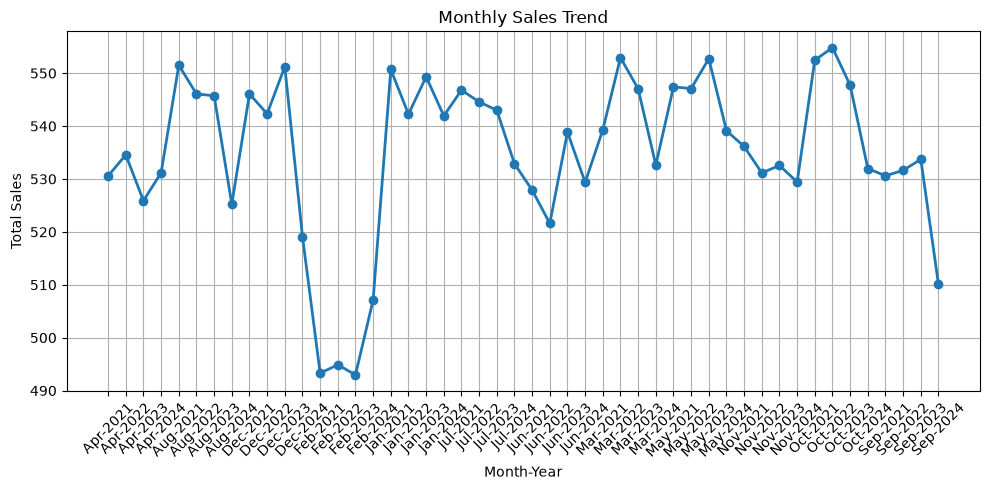

In [7]:
df['actual_date'] = pd.to_datetime(df['actual_date'])

# Create Month-Year column
df['month_year'] = df['actual_date'].dt.strftime('%b-%Y')

# Group by Month-Year
monthly_sales = df.groupby('month_year')['total_sales'].sum()

# Plot
plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index,
         monthly_sales.values,
         marker='o',
         linewidth=2)

plt.title('Monthly Sales Trend')
plt.xlabel('Month-Year')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

# Step 5: Sales by Day of the Week.

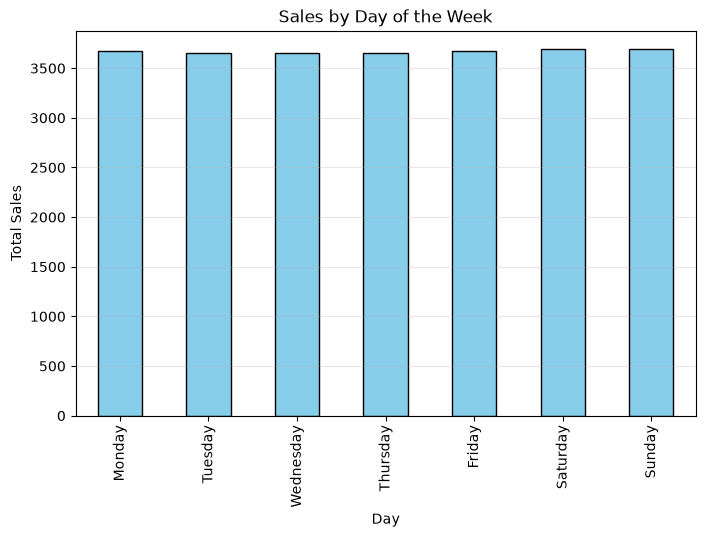

In [8]:
df['actual_date'] = pd.to_datetime(df['actual_date'])

# Create day_of_week column
df['day_of_week'] = df['actual_date'].dt.day_name()

# Group by day of week
sales_by_day = df.groupby('day_of_week')['total_sales'].sum()

# Order days correctly
days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

sales_by_day = sales_by_day.reindex(days_order)

# Plot
plt.figure(figsize=(8,5))

sales_by_day.plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Sales by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Total Sales')

plt.grid(axis='y', alpha=0.3)

plt.show()

# Step 6: Sales by Region.

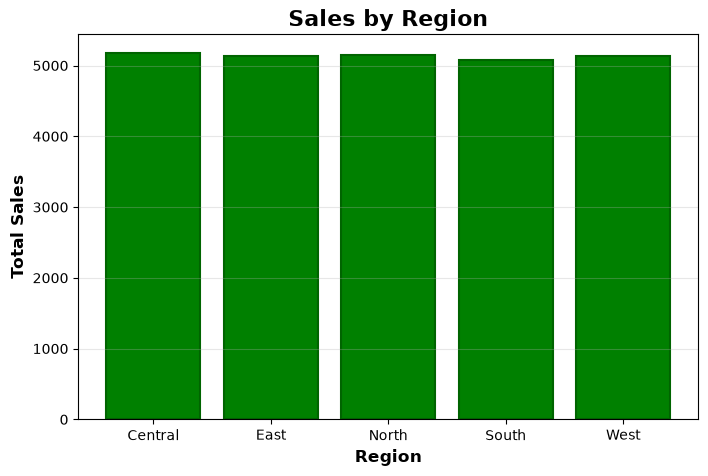

In [9]:
region_sales = df.groupby('region')['total_sales'].sum()

# Create the bar chart
plt.figure(figsize=(8, 5))
plt.bar(
    region_sales.index,
    region_sales.values,
    color='green',
    edgecolor='darkgreen',
    linewidth=1.5
)

# Add labels and title
plt.title('Sales by Region', fontsize=16, fontweight='bold')
plt.xlabel('Region', fontsize=12, fontweight='bold')
plt.ylabel('Total Sales', fontsize=12, fontweight='bold')

plt.grid(axis='y', alpha=0.3)

plt.show()

# Step 7: Sales Performance by Brand.

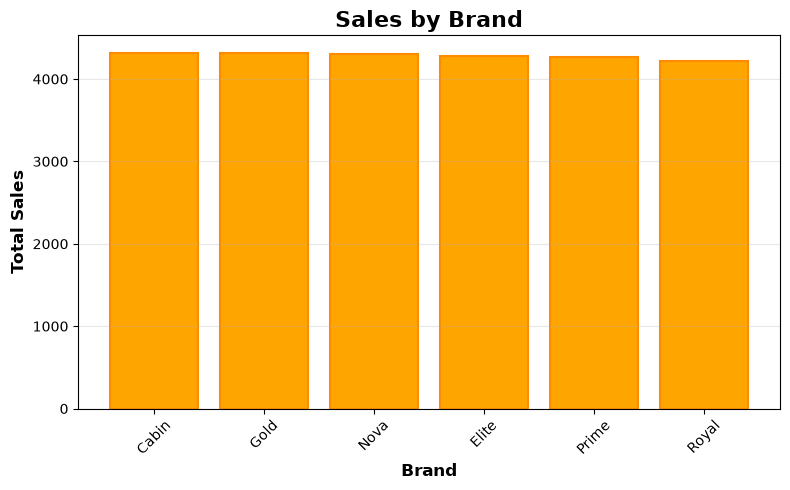

In [10]:
brand_sales = df.groupby('brand')['total_sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))

plt.bar(
    brand_sales.index,
    brand_sales.values,
    color='orange',
    edgecolor='darkorange',
    linewidth=1.5
)

plt.title('Sales by Brand', fontsize=16, fontweight='bold')
plt.xlabel('Brand', fontsize=12, fontweight='bold')
plt.ylabel('Total Sales', fontsize=12, fontweight='bold')

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()